# TP Jour 4 – UC-08 : analyse des données et visualisation

**Retail Intelligence Platform** – IPSSI, Mastère Développement, Data & IA

**Objectif** : partir des données Silver et Gold produites au TP3 (UC-06), calculer les KPI définis en UC-01, produire des statistiques descriptives, répondre à des questions métier avec des graphiques, puis formuler des constats sans dire plus que ce que les données permettent.

**Parcours** : B – local / open source (PySpark pour les calculs, Pandas pour les petits tableaux de résultats, Matplotlib pour les graphiques).

| Partie | Étape UC-08 | Rôle |
|---|---|---|
| 0 | – | Imports, paramètres (`config/parametres_tp4.json`), session Spark |
| 1 | Étape 1 | Sélection des jeux Silver / Gold : nom, provenance, format, schéma, granularité, contrôles qualité |
| 2 | Étape 2 | Dictionnaire des KPI et calcul des KPI (Silver), recoupés avec le Gold |
| 3 | Étape 3 | Statistiques descriptives (lignes de vente et tickets) |
| 4 | Étape 4 | Trois analyses métier issues de l'UC-01 |
| 5 | Étape 5 | Quatre visualisations exportées en PNG |
| 6 | Étape 6 | Constats, limites et recommandations |
| 7 | – | Tests de validation UC-08 (§ 12.1 du TP) |

Tous les calculs sont faits par **Spark**. Seuls de **petits résultats agrégés** (au plus 8 910 lignes, une par ticket) passent dans Pandas avec `toPandas()`.

## 0. Imports, paramètres et session Spark

Les chemins viennent de `config/parametres_tp4.json` : le notebook lit directement les dossiers Silver / Gold du TP3, sans les recopier.

In [1]:
import json
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import pyspark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# ---------- Parametres et chemins ----------
RACINE = Path.cwd()
while not (RACINE / "config" / "parametres_tp4.json").exists():
    if RACINE.parent == RACINE:
        raise RuntimeError("config/parametres_tp4.json introuvable : lancer le notebook depuis le dépôt")
    RACINE = RACINE.parent
PARAMS = json.loads((RACINE / "config" / "parametres_tp4.json").read_text())


def chemin(cle):
    return (RACINE / PARAMS["chemins"][cle]).resolve()


LOCAL = "file://"  # sans ce prefixe, Spark chercherait dans HDFS (fs.defaultFS = hdfs://localhost:9000)
SILVER, GOLD = chemin("silver"), chemin("gold")
OUTPUTS, VISU = chemin("outputs"), chemin("visualisations")
OUTPUTS.mkdir(parents=True, exist_ok=True)
VISU.mkdir(parents=True, exist_ok=True)
for dossier in (SILVER, GOLD):
    if not dossier.is_dir():
        raise FileNotFoundError(f"{dossier} absent : lancer d'abord ./run_pipeline.sh (pipeline du Jour 3)")

A = PARAMS["analyse"]
SOURCE_GRAPHE = "Source : TPCx-BB (synthétique), store_sales échantillon 10 % des tickets – zone {} du TP3"

# ---------- Session Spark (ressources reduites) ----------
constructeur = SparkSession.builder.appName("TP4-Retail-Intelligence").master(PARAMS["spark"]["master"])
for cle, valeur in PARAMS["spark"]["config"].items():
    constructeur = constructeur.config(cle, valeur)
spark = constructeur.getOrCreate()
spark.sparkContext.setLogLevel(PARAMS["spark"]["niveau_journal"])


def lire(zone, jeu):
    return spark.read.parquet(LOCAL + str((SILVER if zone == "silver" else GOLD) / jeu))


pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
print("Spark      :", spark.version, PARAMS["spark"]["master"])
print("PySpark    :", pyspark.__version__)
print("Pandas     :", pd.__version__)
print("Matplotlib :", matplotlib.__version__)
print("Silver     :", SILVER)
print("Gold       :", GOLD)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/19 14:27:53 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark      : 4.3.0 local[2]
PySpark    : 4.3.0
Pandas     : 2.3.3
Matplotlib : 3.11.2
Silver     : /home/lolorigolo/DEV/J1_Retail_Intelligence/tp3_lolo/retail-intelligence-platform/data/silver
Gold       : /home/lolorigolo/DEV/J1_Retail_Intelligence/tp3_lolo/retail-intelligence-platform/data/gold


## 1. Étape 1 – Sélectionner les données

On retient **un jeu Silver** et **quatre jeux Gold**, tous produits au TP3 :

| Jeu | Zone | Usage dans ce notebook |
|---|---|---|
| `sales_enriched` | Silver | KPI recalculés à la ligne, statistiques descriptives, distribution des tickets |
| `ca_annuel` | Gold | Recoupement des KPI annuels |
| `ca_mensuel` | Gold | Analyse 1 : évolution mensuelle du CA |
| `ca_marge_par_categorie` | Gold | Analyse 2 : contribution des catégories |
| `ca_marge_par_magasin` | Gold | Analyse 3 : différences entre magasins |

Pour chaque jeu on vérifie : le **format** (fichiers `.parquet`, signature `PAR1`), la **provenance** (colonnes `_source_*` / `_sources_silver` écrites au TP3), le **schéma**, la **granularité** (la clé annoncée est-elle unique ?) et les **contrôles qualité** du rapport TP3.

In [2]:
QUALITE = json.loads(chemin("rapport_qualite").read_text())["controles"]

JEUX = [
    {"jeu": "sales_enriched", "zone": "silver", "cle": ["ticket_id", "produit_sk", "ligne_ticket"],
     "granularite": "une ligne d'article vendu sur un ticket de caisse",
     "usage": "KPI a la ligne, statistiques descriptives, distribution des tickets",
     "pourquoi": "seul jeu au grain le plus fin, deja joint aux produits / magasins / dates : permet de recalculer tous les KPI"},
    {"jeu": "ca_annuel", "zone": "gold", "cle": ["annee"], "granularite": "une annee",
     "usage": "recoupement des KPI annuels",
     "pourquoi": "KPI deja agreges par annee : sert de reference pour verifier les calculs Silver"},
    {"jeu": "ca_mensuel", "zone": "gold", "cle": ["annee", "mois"], "granularite": "un mois (annee, mois)",
     "usage": "analyse 1 : evolution mensuelle", "pourquoi": "CA mensuel + CA du meme mois N-1 + indicateur de mois incomplet"},
    {"jeu": "ca_marge_par_categorie", "zone": "gold", "cle": ["categorie_id"], "granularite": "une categorie de produits",
     "usage": "analyse 2 : contribution des categories", "pourquoi": "9 lignes, part du CA deja calculee : lisible en barres"},
    {"jeu": "ca_marge_par_magasin", "zone": "gold", "cle": ["magasin_sk"], "granularite": "un magasin",
     "usage": "analyse 3 : differences entre magasins", "pourquoi": "12 magasins avec CA, transactions et panier moyen"},
]

donnees, inventaire = {}, []
for j in JEUX:
    dossier = (SILVER if j["zone"] == "silver" else GOLD) / j["jeu"]
    fichiers = sorted(dossier.rglob("*.parquet"))
    signature_ok = all(f.read_bytes()[:4] == b"PAR1" and f.read_bytes()[-4:] == b"PAR1" for f in fichiers)
    df = lire(j["zone"], j["jeu"])
    donnees[j["jeu"]] = df
    nb = df.count()
    cle_unique = df.select(*j["cle"]).distinct().count() == nb
    colonne_prov = "_source_fichier" if "_source_fichier" in df.columns else "_sources_silver"
    provenance = " ; ".join(sorted(r[0] for r in df.select(colonne_prov).distinct().collect()))
    traitement = " ; ".join(sorted(r[0] for r in df.select("_traitement").distinct().collect()))
    nom_qualite = j["jeu"] if j["zone"] == "silver" else "gold." + j["jeu"]
    ctrl = [c for c in QUALITE if c["jeu"] == nom_qualite]
    inventaire.append({
        "jeu": j["jeu"], "zone": j["zone"].capitalize(),
        "chemin": str(dossier.relative_to(chemin("projet_tp3"))),
        "format": f"Parquet ({len(fichiers)} fichier(s), signature PAR1 {'OK' if signature_ok else 'KO'})",
        "taille_ko": round(sum(f.stat().st_size for f in fichiers) / 1024, 1),
        "lignes": nb, "colonnes": len(df.columns),
        "granularite": j["granularite"], "cle": " + ".join(j["cle"]),
        "cle_unique": cle_unique,
        "provenance": provenance.replace(str(Path.home()), "~"), "traitement": traitement,
        "controles_qualite_tp3": f"{sum(c['statut'] == 'OK' for c in ctrl)} OK, {sum(c['statut'] != 'OK' for c in ctrl)} alerte(s)",
        "usage": j["usage"], "pourquoi_adapte": j["pourquoi"],
    })

pdf_inventaire = pd.DataFrame(inventaire)
pdf_inventaire.to_csv(OUTPUTS / "inventaire_jeux.csv", index=False)
assert pdf_inventaire["cle_unique"].all(), "une cle annoncee n'est pas unique : granularite a revoir"
pdf_inventaire[["jeu", "zone", "format", "lignes", "colonnes", "granularite", "cle", "cle_unique", "controles_qualite_tp3"]]

,jeu,zone,format,lignes,colonnes,granularite,cle,cle_unique,controles_qualite_tp3
0,sales_enriched,Silver,"Parquet (10 fichier(s), signature PAR1 OK)",66593,42,une ligne d'article vendu sur un ticket de caisse,ticket_id + produit_sk + ligne_ticket,True,"17 OK, 1 alerte(s)"
1,ca_annuel,Gold,"Parquet (1 fichier(s), signature PAR1 OK)",5,15,une annee,annee,True,"6 OK, 0 alerte(s)"
2,ca_mensuel,Gold,"Parquet (1 fichier(s), signature PAR1 OK)",60,18,"un mois (annee, mois)",annee + mois,True,"6 OK, 1 alerte(s)"
3,ca_marge_par_categorie,Gold,"Parquet (1 fichier(s), signature PAR1 OK)",9,17,une categorie de produits,categorie_id,True,"8 OK, 0 alerte(s)"
4,ca_marge_par_magasin,Gold,"Parquet (1 fichier(s), signature PAR1 OK)",12,19,un magasin,magasin_sk,True,"7 OK, 0 alerte(s)"


In [3]:
pdf_inventaire[["jeu", "provenance", "traitement", "usage", "pourquoi_adapte"]]

,jeu,provenance,traitement,usage,pourquoi_adapte
0,sales_enriched,~/DEV/J1_Retail_Intelligence/tp3_lolo/retail-i...,transformations/enrichment/enrichissement_vent...,"KPI a la ligne, statistiques descriptives, dis...","seul jeu au grain le plus fin, deja joint aux ..."
1,ca_annuel,silver/sales_enriched,transformations/aggregation/agregations_gold.i...,recoupement des KPI annuels,KPI deja agreges par annee : sert de reference...
2,ca_mensuel,silver/sales_enriched,transformations/aggregation/agregations_gold.i...,analyse 1 : evolution mensuelle,CA mensuel + CA du meme mois N-1 + indicateur ...
3,ca_marge_par_categorie,silver/sales_enriched,transformations/aggregation/agregations_gold.i...,analyse 2 : contribution des categories,"9 lignes, part du CA deja calculee : lisible e..."
4,ca_marge_par_magasin,silver/sales_enriched,transformations/aggregation/agregations_gold.i...,analyse 3 : differences entre magasins,"12 magasins avec CA, transactions et panier moyen"


### Schémas

Schéma réel de chaque jeu, relu par Spark (on ne suppose aucune colonne).

In [4]:
for nom, df in donnees.items():
    print(f"===== {nom}")
    df.printSchema()

===== sales_enriched
root
 |-- date_vente: date (nullable = true)
 |-- trimestre: integer (nullable = true)
 |-- mois: integer (nullable = true)
 |-- jour_semaine: string (nullable = true)
 |-- heure_sk: long (nullable = true)
 |-- ticket_id: long (nullable = true)
 |-- ligne_ticket: integer (nullable = true)
 |-- client_sk: long (nullable = true)
 |-- promotion_sk: long (nullable = true)
 |-- produit_sk: long (nullable = true)
 |-- produit_id: string (nullable = true)
 |-- nom_produit: string (nullable = true)
 |-- categorie_id: integer (nullable = true)
 |-- categorie: string (nullable = true)
 |-- sous_categorie: string (nullable = true)
 |-- marque: string (nullable = true)
 |-- magasin_sk: long (nullable = true)
 |-- magasin_id: string (nullable = true)
 |-- nom_magasin: string (nullable = true)
 |-- ville: string (nullable = true)
 |-- etat: string (nullable = true)
 |-- quantite: integer (nullable = true)
 |-- prix_catalogue_unitaire: decimal(7,2) (nullable = true)
 |-- prix_ven

### Alertes qualité du TP3 qui concernent ces jeux

Les contrôles du TP3 (`outputs/rapport_qualite.json`) ne donnent aucun KO. Les alertes ci-dessous sont des **limites connues** à garder en tête pour interpréter les résultats (le jeu `sales` est la source de `sales_enriched`).

In [5]:
alertes = pd.DataFrame([c for c in QUALITE if c["statut"] != "OK" and c["jeu"] in
                        ("sales", "sales_enriched", "stores", "gold.ca_mensuel")])
alertes[["jeu", "controle", "resultat", "action"]]

,jeu,controle,resultat,action
0,sales,ss_cdemo_sk renseigne,20 (0.03 %) vide(s),Tolere (< 1 %) : la colonne ne sert pas aux in...
1,sales,ss_hdemo_sk renseigne,25 (0.04 %) vide(s),Tolere (< 1 %) : la colonne ne sert pas aux in...
2,sales,ss_addr_sk renseigne,75 (0.11 %) vide(s),Tolere (< 1 %) : la colonne ne sert pas aux in...
3,sales,ss_promo_sk renseigne,15 (0.02 %) vide(s),Tolere (< 1 %) : la colonne ne sert pas aux in...
4,stores,s_closed_date renseigne,12 (100.00 %) vide(s),Valeur source incoherente remplacee par null (...
5,sales,ticket+produit seul n'est pas une cle,406 ligne(s) repetee(s),Conservees et numerotees par ss_ligne_ticket (...
6,sales,marge positive,49559 (74.42 %) hors regle,"Conservee (R7), indicateur ss_marge_negative :..."
7,sales,vente au-dessus du cout,46271 (69.48 %) hors regle,"Conservee : vente a perte, cas metier possible"
8,sales,prix de vente non nul,356 (0.53 %) hors regle,"Conservee (R7), indicateur ss_prix_nul : artic..."
9,stores,horaires d'ouverture coherents,1 (8.33 %) hors regle,"Conservee (8AM-8AM : ouvert 24 h/24 ?), colonn..."


## 2. Étape 2 – Vérifier les KPI

Les KPI viennent du dictionnaire UC-01 (`01_UC01_besoin_exploration/UC01_dictionnaire_KPI.md`). Au TP3, **seul le canal magasin (`store_sales`)** a été transformé en Silver / Gold : les parties « web » des formules UC-01 ne sont donc pas calculables ici. Les colonnes sont celles, renommées, de `sales_enriched`.

In [6]:
KPI = [
    {"kpi": "KPI-01 Chiffre d'affaires (CA)", "definition": "Argent encaisse sur les ventes, remises deduites, hors taxes",
     "formule": "SUM(montant_net_paye)", "champs": "montant_net_paye (= ss_net_paid)",
     "filtres": "canal magasin uniquement ; echantillon 10 % des tickets ; retours non deduits",
     "granularite": "global, annee, mois, magasin, categorie", "unite": "EUR (supposee)",
     "limites": "CA ne veut pas dire rentabilite ; total de l'echantillon, pas du reseau entier", "statut": "calcule"},
    {"kpi": "KPI-02 Nombre de transactions", "definition": "Nombre d'achats (tickets de caisse)",
     "formule": "COUNT(DISTINCT ticket_id)", "champs": "ticket_id (= ss_ticket_number)",
     "filtres": "canal magasin uniquement", "granularite": "global, annee, mois, magasin",
     "unite": "tickets", "limites": "un ticket n'est pas un client ; ne jamais compter les lignes", "statut": "calcule"},
    {"kpi": "KPI-03 Panier moyen", "definition": "Montant moyen depense par ticket",
     "formule": "KPI-01 / KPI-02", "champs": "montant_net_paye, ticket_id",
     "filtres": "canal magasin uniquement", "granularite": "global, annee, magasin",
     "unite": "EUR par ticket", "limites": "moyenne sensible aux gros tickets : comparer avec la mediane (etape 3)", "statut": "calcule"},
    {"kpi": "KPI-04 Quantites vendues", "definition": "Nombre d'articles vendus",
     "formule": "SUM(quantite)", "champs": "quantite (= ss_quantity)", "filtres": "quantite > 0 (regle TP3)",
     "granularite": "global, annee, categorie", "unite": "articles",
     "limites": "additionne des articles tres differents ; retours non deduits", "statut": "calcule"},
    {"kpi": "KPI-05 Taux de remise", "definition": "Part du prix catalogue enlevee par les remises",
     "formule": "SUM(montant_remise) / SUM(montant_catalogue) x 100",
     "champs": "montant_remise (= ss_ext_discount_amt), montant_catalogue (= ss_ext_list_price)",
     "filtres": "canal magasin uniquement", "granularite": "global, annee, mois", "unite": "%",
     "limites": "taux tres eleve (donnees generees) : a comparer dans le temps, pas a juger", "statut": "calcule"},
    {"kpi": "KPI-06 Evolution du CA", "definition": "Variation du CA par rapport a la meme periode N-1",
     "formule": "(CA N - CA N-1) / CA N-1 x 100", "champs": "montant_net_paye, annee, mois",
     "filtres": "pas de N-1 pour 2001 ; decembre 2005 incomplet (jusqu'au 13/12)",
     "granularite": "annee, mois", "unite": "%",
     "limites": "depend des saisons ; une hausse peut venir d'un magasin ouvert, pas d'une vraie croissance", "statut": "calcule"},
    {"kpi": "Marge (non retenue)", "definition": "CA - cout d'achat",
     "formule": "SUM(marge) (= ss_net_profit)", "champs": "marge, cout_total",
     "filtres": "-", "granularite": "-", "unite": "EUR",
     "limites": "74 % des lignes ont une marge negative (alerte TP3) : couts generes, non qualifies -> pas utilisee pour conclure",
     "statut": "non retenu"},
    {"kpi": "Part du CA web / magasin (non calculable)", "definition": "Repartition du CA par canal",
     "formule": "CA canal / CA total", "champs": "ws_net_paid (web_sales)", "filtres": "-", "granularite": "-", "unite": "%",
     "limites": "web_sales n'a pas ete transforme au TP3 : le canal n'est pas identifiable dans Silver / Gold",
     "statut": "non calculable"},
]
pdf_kpi_dico = pd.DataFrame(KPI)
pdf_kpi_dico.to_csv(OUTPUTS / "kpi_dictionnaire.csv", index=False)
pdf_kpi_dico[["kpi", "formule", "granularite", "unite", "statut"]]

,kpi,formule,granularite,unite,statut
0,KPI-01 Chiffre d'affaires (CA),SUM(montant_net_paye),"global, annee, mois, magasin, categorie",EUR (supposee),calcule
1,KPI-02 Nombre de transactions,COUNT(DISTINCT ticket_id),"global, annee, mois, magasin",tickets,calcule
2,KPI-03 Panier moyen,KPI-01 / KPI-02,"global, annee, magasin",EUR par ticket,calcule
3,KPI-04 Quantites vendues,SUM(quantite),"global, annee, categorie",articles,calcule
4,KPI-05 Taux de remise,SUM(montant_remise) / SUM(montant_catalogue) x...,"global, annee, mois",%,calcule
5,KPI-06 Evolution du CA,(CA N - CA N-1) / CA N-1 x 100,"annee, mois",%,calcule
6,Marge (non retenue),SUM(marge) (= ss_net_profit),-,EUR,non retenu
7,Part du CA web / magasin (non calculable),CA canal / CA total,-,%,non calculable


### Calcul des KPI à partir du Silver

Les KPI sont recalculés **depuis les lignes de vente** (`sales_enriched`) par année et sur toute la période. Le panier moyen utilise le nombre de **tickets distincts**, pas le nombre de lignes.

In [7]:
ventes = donnees["sales_enriched"]


def kpi(df, *dimensions):
    return (df.groupBy(*dimensions)
            .agg(F.sum("montant_net_paye").alias("chiffre_affaires"),
                 F.countDistinct("ticket_id").alias("nb_transactions"),
                 F.sum("quantite").alias("quantites_vendues"),
                 F.sum("montant_remise").alias("remises"),
                 F.sum("montant_catalogue").alias("montant_catalogue"),
                 F.count("*").alias("nb_lignes"))
            .withColumn("panier_moyen", F.round(F.col("chiffre_affaires") / F.col("nb_transactions"), 2))
            .withColumn("taux_remise_pct", F.round(F.col("remises") / F.col("montant_catalogue") * 100, 2)))


par_annee = kpi(ventes, "annee").orderBy("annee").toPandas()
total = kpi(ventes.withColumn("annee", F.lit("2001-2005")), "annee").toPandas()

pdf_kpi = pd.concat([par_annee.astype({"annee": str}), total], ignore_index=True)
for c in ["chiffre_affaires", "remises", "montant_catalogue", "panier_moyen", "taux_remise_pct"]:
    pdf_kpi[c] = pdf_kpi[c].astype(float)
ca = pdf_kpi["chiffre_affaires"]
pdf_kpi["evolution_ca_pct"] = (ca / ca.shift(1) - 1).mul(100).round(2)
pdf_kpi.loc[pdf_kpi["annee"].isin(["2001", "2001-2005"]), "evolution_ca_pct"] = None

# Les donnees s'arretent le 13/12/2005 : evolution recalculee a periode egale (1er janvier -> 13 decembre)
fin = pd.Timestamp(A["date_fin_donnees"])
meme_periode = (ventes.filter((F.month("date_vente") < fin.month)
                              | ((F.month("date_vente") == fin.month) & (F.dayofmonth("date_vente") <= fin.day)))
                .groupBy("annee").agg(F.sum("montant_net_paye").alias("ca")).orderBy("annee").toPandas())
ca_egal = meme_periode["ca"].astype(float)
evol_egale = dict(zip(meme_periode["annee"].astype(str), (ca_egal / ca_egal.shift(1) - 1).mul(100).round(2)))
pdf_kpi[f"evolution_ca_1er_janv_{fin.day}_dec_pct"] = pdf_kpi["annee"].map(evol_egale)
pdf_kpi["remarque"] = ""
pdf_kpi.loc[pdf_kpi["annee"] == "2001", "remarque"] = "pas d'annee N-1"
pdf_kpi.loc[pdf_kpi["annee"] == "2005", "remarque"] = "annee incomplete (donnees jusqu'au 13/12/2005)"
pdf_kpi = pdf_kpi.rename(columns={"annee": "periode"})
pdf_kpi.to_csv(OUTPUTS / "kpi.csv", index=False)
pdf_kpi[["periode", "chiffre_affaires", "nb_transactions", "panier_moyen", "quantites_vendues",
         "taux_remise_pct", "evolution_ca_pct", f"evolution_ca_1er_janv_{fin.day}_dec_pct", "remarque"]]

,periode,chiffre_affaires,nb_transactions,panier_moyen,quantites_vendues,taux_remise_pct,evolution_ca_pct,evolution_ca_1er_janv_13_dec_pct,remarque
0,2001,2.340466e+07,1800,13002.59,677319,50.05,NaN,NaN,pas d'annee N-1
1,2002,2.303797e+07,1799,12805.99,681325,50.26,-1.57,-1.68,
2,2003,2.359145e+07,1799,13113.65,686147,49.67,2.40,2.83,
3,2004,2.371377e+07,1803,13152.40,695055,50.05,0.52,0.19,
4,2005,2.200433e+07,1709,12875.56,646230,49.85,-7.21,-2.53,annee incomplete (donnees jusqu'au 13/12/2005)
5,2001-2005,1.157522e+08,8910,12991.27,3386076,49.98,NaN,NaN,


### Recoupement Silver / Gold

Les KPI annuels recalculés depuis le Silver doivent être **identiques** à ceux de la table Gold `ca_annuel`. Si les deux chemins de calcul donnent le même résultat, le calcul est fiable et reproductible.

In [8]:
COLONNES_KPI = ["chiffre_affaires", "nb_transactions", "quantites_vendues", "panier_moyen", "taux_remise_pct"]
# toPandas() seulement sur les colonnes utiles (pas les colonnes techniques _traitement, _date_traitement...)
gold_annuel = donnees["ca_annuel"].select("annee", *COLONNES_KPI).orderBy("annee").toPandas()
controles_kpi = []
for col in COLONNES_KPI:
    silver_vals = par_annee[col].astype(float).round(2).tolist()
    gold_vals = gold_annuel[col].astype(float).round(2).tolist()
    controles_kpi.append({"kpi": col, "silver = gold": silver_vals == gold_vals})
# Un ticket n'a qu'une date : la somme des tickets par annee = nombre total de tickets
controles_kpi.append({"kpi": "transactions annuelles additives",
                      "silver = gold": int(par_annee["nb_transactions"].sum()) == int(total["nb_transactions"][0])})
pdf_ctrl_kpi = pd.DataFrame(controles_kpi)
assert pdf_ctrl_kpi["silver = gold"].all(), pdf_ctrl_kpi
pdf_ctrl_kpi

,kpi,silver = gold
0,chiffre_affaires,True
1,nb_transactions,True
2,quantites_vendues,True
3,panier_moyen,True
4,taux_remise_pct,True
5,transactions annuelles additives,True


## 3. Étape 3 – Statistiques descriptives

Deux niveaux de granularité, à **ne pas mélanger** :

* **ligne de vente** (`sales_enriched`, 66 593 lignes) : quantité, prix unitaire, montant payé, remise ;
* **ticket** (agrégation Spark par `ticket_id`, 8 910 tickets) : montant du ticket, nombre d'articles, nombre de lignes.

Les sommes ne sont données que pour les mesures **additives** (pas pour un prix unitaire). La médiane est exacte (`percentile`).

In [9]:
def statistiques(df, colonnes, niveau, additives):
    lignes = []
    for c in colonnes:
        r = df.agg(F.count(c).alias("n"), F.sum(F.col(c).isNull().cast("int")).alias("vides"),
                   F.min(c).alias("min"), F.max(c).alias("max"), F.avg(c).alias("moyenne"),
                   F.expr(f"percentile({c}, 0.5)").alias("mediane"), F.stddev(c).alias("ecart_type"),
                   F.sum(c).alias("somme")).first()
        lignes.append({"niveau": niveau, "variable": c, "nb_valeurs": r["n"], "nb_vides": r["vides"],
                       "min": float(r["min"]), "max": float(r["max"]), "moyenne": round(float(r["moyenne"]), 2),
                       "mediane": round(float(r["mediane"]), 2), "ecart_type": round(float(r["ecart_type"]), 2),
                       "somme": float(r["somme"]) if c in additives else None})
    return lignes


tickets = (ventes.groupBy("ticket_id")
           .agg(F.sum("montant_net_paye").alias("montant_ticket"),
                F.sum("quantite").alias("articles_par_ticket"),
                F.count("*").alias("lignes_par_ticket")))

stats = (statistiques(ventes, ["quantite", "prix_vente_unitaire", "montant_net_paye", "montant_remise"], "ligne de vente",
                      additives={"quantite", "montant_net_paye", "montant_remise"})
         + statistiques(tickets, ["montant_ticket", "articles_par_ticket", "lignes_par_ticket"], "ticket",
                        additives={"montant_ticket", "articles_par_ticket"}))
pdf_stats = pd.DataFrame(stats)
pdf_stats.to_csv(OUTPUTS / "statistiques.csv", index=False)
pdf_stats

,niveau,variable,nb_valeurs,nb_vides,min,max,moyenne,mediane,ecart_type,somme
0,ligne de vente,quantite,66593,0,1.0,100.00,50.85,51.00,28.92,3.386076e+06
1,ligne de vente,prix_vente_unitaire,66593,0,0.0,194.54,37.83,27.44,34.57,NaN
2,ligne de vente,montant_net_paye,66593,0,0.0,17746.82,1738.20,882.39,2189.21,1.157522e+08
3,ligne de vente,montant_remise,66593,0,0.0,17233.30,1924.95,1052.20,2286.15,1.281885e+08
4,ticket,montant_ticket,8910,0,0.0,60903.90,12991.27,11718.01,9111.99,1.157522e+08
5,ticket,articles_par_ticket,8910,0,1.0,1020.00,380.03,373.00,217.79,3.386076e+06
6,ticket,lignes_par_ticket,8910,0,1.0,14.00,7.47,7.00,4.02,NaN


### Répartition par catégorie et évolution temporelle des volumes

In [10]:
repartition = (ventes.groupBy("categorie")
               .agg(F.count("*").alias("nb_lignes"), F.sum("quantite").alias("quantites"),
                    F.countDistinct("produit_sk").alias("nb_produits"))
               .orderBy(F.desc("nb_lignes")).toPandas())
repartition["part_lignes_pct"] = (repartition["nb_lignes"] / repartition["nb_lignes"].sum() * 100).round(2)
repartition.to_csv(OUTPUTS / "repartition_categories.csv", index=False)
repartition

,categorie,nb_lignes,quantites,nb_produits,part_lignes_pct
0,Music,30103,1530364,7164,45.20
1,Books,17707,898730,4688,26.59
2,Movies & TV,4319,217332,1121,6.49
3,Electronics,3272,163312,609,4.91
4,Clothing & Accessories,3198,165362,528,4.80
5,Home & Kitchen,2423,125083,419,3.64
6,Sports & Outdoors,2356,120954,401,3.54
7,Tools & Home Improvement,1635,83765,358,2.46
8,Toys & Games,1580,81174,348,2.37


In [11]:
volumes_annuels = (ventes.groupBy("annee")
                   .agg(F.count("*").alias("nb_lignes"), F.countDistinct("ticket_id").alias("nb_tickets"),
                        F.countDistinct("date_vente").alias("nb_jours_de_vente"),
                        F.min("date_vente").alias("premiere_vente"), F.max("date_vente").alias("derniere_vente"))
                   .orderBy("annee").toPandas())
volumes_annuels

,annee,nb_lignes,nb_tickets,nb_jours_de_vente,premiere_vente,derniere_vente
0,2001,13381,1800,365,2001-01-01,2001-12-31
1,2002,13404,1799,365,2002-01-01,2002-12-31
2,2003,13463,1799,365,2003-01-01,2003-12-31
3,2004,13590,1803,366,2004-01-01,2004-12-31
4,2005,12755,1709,347,2005-01-01,2005-12-13


**Lecture des statistiques**

* **Lignes de vente** : la quantité va de 1 à 100 (moyenne 50,85, médiane 51), ce qui correspond à une distribution à peu près uniforme. Le montant payé par ligne est très dissymétrique : la moyenne (1 738,20 EUR) vaut le double de la médiane (882,39 EUR), car quelques lignes très élevées (jusqu'à 17 746,82 EUR) tirent la moyenne vers le haut.
* **Tickets** : 7,47 lignes et **380 articles** par ticket en moyenne, pour un montant moyen de **12 991 EUR** (médiane 11 718 EUR). Ces valeurs ne sont pas réalistes pour un ticket de caisse : elles viennent du générateur TPCx-BB. On garde la démarche, mais on ne présente pas ce « panier » comme un comportement client réel.
* **Catégories** : Music (45,2 % des lignes) et Books (26,6 %) représentent à elles deux 72 % des lignes.
* **Temps** : environ 13 400 lignes et 1 800 tickets par an de 2001 à 2004. Les ventes ont lieu tous les jours de l'année. 2005 s'arrête au **13/12/2005** (347 jours), ce qui explique ses volumes plus faibles.
* Aucune valeur vide dans les colonnes analysées, ce qui confirme les contrôles du TP3.

## 4. Étape 4 – Analyses métier

Trois questions de l'UC-01 (`UC01_questions_decisionnelles.md`), choisies parce que les données nécessaires existent dans le Silver / Gold :

| # | Profil | Question UC-01 | Priorité |
|---|---|---|---|
| A1 | P1 Direction générale | Comment évolue le chiffre d'affaires chaque mois et par rapport à l'année d'avant ? | Indispensable |
| A2 | P4 Direction commerciale | Quels produits et quelles catégories génèrent le plus de chiffre d'affaires ? | Indispensable |
| A3 | P1 / P4 | Quelles différences observe-t-on entre les magasins ? | Utile |

La question « part magasin / web » (P1, indispensable) **n'est pas traitable** : `web_sales` n'a pas été transformé au TP3.

### A1 – Évolution mensuelle du chiffre d'affaires

* **Données** : Gold `ca_mensuel` (60 mois, de janvier 2001 à décembre 2005).
* **Méthode** : CA mensuel (KPI-01) ; évolution par rapport au même mois de l'année précédente (KPI-06, colonne `evolution_ca_pct` du Gold) ; profil saisonnier = CA moyen de chaque mois de l'année sur les années complètes 2001-2004 ; décembre 2005 exclu des comparaisons (`mois_incomplet`).

In [12]:
mensuel = (donnees["ca_mensuel"].orderBy("annee", "mois")
           .select("annee", "mois", "chiffre_affaires", "nb_transactions", "panier_moyen",
                   "ca_annee_precedente", "evolution_ca_pct", "mois_incomplet").toPandas())
for c in ["chiffre_affaires", "panier_moyen", "ca_annee_precedente", "evolution_ca_pct"]:
    mensuel[c] = mensuel[c].astype(float)
mensuel["periode"] = pd.to_datetime(dict(year=mensuel["annee"], month=mensuel["mois"], day=1))

# Controle : le total des mois = le CA total du Silver
assert round(mensuel["chiffre_affaires"].sum(), 2) == round(float(total["chiffre_affaires"][0]), 2)

complets = mensuel[~mensuel["mois_incomplet"]]
for libelle, i in [("Mois le plus fort  ", complets["chiffre_affaires"].idxmax()),
                   ("Mois le plus faible", complets["chiffre_affaires"].idxmin())]:
    print(f"{libelle}: {complets.loc[i, 'mois']:02d}/{complets.loc[i, 'annee']} -> {complets.loc[i, 'chiffre_affaires']:,.2f}")
print("CA mensuel moyen   :", round(complets["chiffre_affaires"].mean(), 2),
      "| ecart-type :", round(complets["chiffre_affaires"].std(), 2),
      "| coefficient de variation :", round(complets["chiffre_affaires"].std() / complets["chiffre_affaires"].mean() * 100, 1), "%")
evol = complets["evolution_ca_pct"].dropna()
print("Evolution N/N-1 (mois) : min", evol.min(), "% | max", evol.max(), "% | mediane", evol.median(), "%",
      "|", int((evol > 0).sum()), "hausses /", int((evol < 0).sum()), "baisses sur", len(evol), "mois")

saison = (mensuel[mensuel["annee"] <= 2004].groupby("mois")["chiffre_affaires"].mean().round(2)
          .rename("ca_moyen_2001_2004").reset_index())
saison["indice_saison"] = (saison["ca_moyen_2001_2004"] / saison["ca_moyen_2001_2004"].mean() * 100).round(1)
mensuel.drop(columns="periode").to_csv(OUTPUTS / "analyse_ca_mensuel.csv", index=False)
saison.to_csv(OUTPUTS / "analyse_saisonnalite.csv", index=False)
saison.T

Mois le plus fort  : 08/2004 -> 2,246,011.71
Mois le plus faible: 06/2005 -> 1,633,335.31
CA mensuel moyen   : 1950855.04 | ecart-type : 119505.75 | coefficient de variation : 6.1 %
Evolution N/N-1 (mois) : min -14.96 % | max 14.94 % | mediane -1.22 % | 22 hausses / 25 baisses sur 47 mois


,0,1,2,3,4,5,6,7,8,9,10,11
mois,1.0,2.00,3.00,4.00,5.00,6.00,7.00,8.00,9.00,10.0,11.00,12.00
ca_moyen_2001_2004,1916963.4,1826447.78,2018218.61,1987840.15,2035133.16,1884324.06,1893680.74,2032456.88,1939632.32,2030764.5,1878007.83,1993493.23
indice_saison,98.2,93.50,103.30,101.80,104.20,96.50,97.00,104.10,99.30,104.0,96.20,102.10


**Résultats A1**

* Le CA annuel est **stable**, entre 23,0 et 23,7 M EUR de 2001 à 2004. L'évolution annuelle reste dans une fourchette de **−1,7 % à +2,8 %** sur une période égale.
* 2005 affiche −7,21 % en données brutes, mais il manque la fin de décembre. **Sur une période égale (1er janvier – 13 décembre), la baisse n'est plus que de −2,53 %.**
* D'un mois à l'autre, le CA varie de ±15 % par rapport au même mois de l'année précédente (de −14,96 % à +14,94 %). Les hausses et les baisses s'équilibrent (22 hausses, 25 baisses sur 47 mois ; médiane −1,22 %). Il n'y a pas de tendance nette.
* Le mois le plus fort est 08/2004 (2,25 M EUR), le plus faible 06/2005 (1,63 M EUR). Le coefficient de variation mensuel est de 6,1 %.
* **Saisonnalité** : l'indice va de 93,5 (février) à 104,2 (mai). Les mois de 31 jours ont un indice moyen d'environ 102, ceux de 30 jours d'environ 98, et février (28 jours) 93,5. L'écart vient donc surtout du **nombre de jours dans le mois**, pas d'un effet saisonnier commercial (le rapport 31/30 vaut 1,033, celui des indices 1,034).

**Interprétation** : l'activité des magasins est plate sur la période. Les variations mensuelles ressemblent à du bruit aléatoire plutôt qu'à des événements commerciaux.

**Limites** : il s'agit d'un échantillon de 10 % des tickets, ce qui augmente les variations mensuelles. Les retours ne sont pas déduits, le canal web n'est pas inclus et les données sont synthétiques.

### A2 – Contribution des catégories au chiffre d'affaires

* **Données** : Gold `ca_marge_par_categorie` (9 catégories) et `top10_produits`.
* **Méthode** : CA par catégorie (KPI-01), part du CA total, nombre de produits vendus, panier moyen des tickets contenant la catégorie. Le CA est rapporté au nombre de produits vendus pour savoir si une catégorie pèse par son assortiment ou par produit.

In [13]:
categories = (donnees["ca_marge_par_categorie"]
              .select("categorie", "chiffre_affaires", "part_ca_pct", "quantites_vendues", "nb_transactions",
                      "nb_produits_vendus", "taux_remise_pct")
              .orderBy(F.desc("chiffre_affaires")).toPandas())
for c in ["chiffre_affaires", "part_ca_pct", "taux_remise_pct"]:
    categories[c] = categories[c].astype(float)
categories["ca_par_produit"] = (categories["chiffre_affaires"] / categories["nb_produits_vendus"]).round(2)
assert round(categories["chiffre_affaires"].sum(), 2) == round(float(total["chiffre_affaires"][0]), 2)
assert abs(categories["part_ca_pct"].sum() - 100) < 0.1
categories.to_csv(OUTPUTS / "analyse_categories.csv", index=False)
print("Ecart entre la 1re et la derniere categorie :",
      round(categories["part_ca_pct"].iloc[0] - categories["part_ca_pct"].iloc[-1], 2), "points de part de CA")
categories

Ecart entre la 1re et la derniere categorie : 42.6 points de part de CA


,categorie,chiffre_affaires,part_ca_pct,quantites_vendues,nb_transactions,nb_produits_vendus,taux_remise_pct,ca_par_produit
0,Music,52109109.95,45.02,1530364,8144,7164,49.99,7273.75
1,Books,30720062.81,26.54,898730,7183,4688,50.04,6552.91
2,Movies & TV,7342177.59,6.34,217332,3298,1121,50.35,6549.67
3,Clothing & Accessories,5768943.01,4.98,165362,2638,528,49.27,10926.03
4,Electronics,5682478.05,4.91,163312,2675,609,49.91,9330.83
5,Home & Kitchen,4291458.75,3.71,125083,2065,419,49.50,10242.14
6,Sports & Outdoors,4138485.68,3.58,120954,2035,401,49.41,10320.41
7,Toys & Games,2901166.65,2.51,81174,1432,348,49.44,8336.69
8,Tools & Home Improvement,2798294.19,2.42,83765,1483,358,51.60,7816.46


In [14]:
top10 = (donnees["top10_produits"] if "top10_produits" in donnees else lire("gold", "top10_produits"))
top10 = top10.select("produit_id", "nom_produit", "categorie", "chiffre_affaires", "quantites_vendues").toPandas()
top10["chiffre_affaires"] = top10["chiffre_affaires"].astype(float)
part_top10 = top10["chiffre_affaires"].sum() / float(total["chiffre_affaires"][0]) * 100
nb_produits = ventes.select("produit_sk").distinct().count()
print(f"Top 10 produits : {part_top10:.2f} % du CA, alors que {nb_produits} produits differents ont ete vendus")
top10

Top 10 produits : 6.92 % du CA, alors que 15636 produits differents ont ete vendus


,produit_id,nom_produit,categorie,chiffre_affaires,quantites_vendues
0,AAAAAAAAAAAAAOUQ,vwPR6l3UPyCIv5bljZbIG9k9YHLajogyqKbd6,Home & Kitchen,1616303.86,46265
1,AAAAAAAAAAAAAOUR,6VxbaI6thqY49zO,Music,1469375.01,42959
2,AAAAAAAAAAAAAOUT,Z2kc,Electronics,1404863.20,40822
3,AAAAAAAAAAAAAOUS,bwTLbeGP8aT6bW7YjgxmDJuCUTlwG1Fz78VewSCYQULiop,Music,1289141.51,38970
4,AAAAAAAAAAAAARDO,bKIpo9aB7pb,Books,402054.46,9632
5,AAAAAAAAAAAAAGWB,ruqCzl5gIq5XGykXpKxbGQ9No16VY,Electronics,374321.55,10069
6,AAAAAAAAAAAAAMSV,Qgphkd7Y,Clothing & Accessories,369091.18,9905
7,AAAAAAAAAAAAAOEG,GF5ZDSvTAEgpWLQJMH1k1obYPkt4i7yTPLRbLKdZOuF,Clothing & Accessories,361308.10,9251
8,AAAAAAAAAAAAAZVY,xc1l,Sports & Outdoors,360449.48,8995
9,AAAAAAAAAAAAADYP,VgMJqL1KvcqYvACAoXJ4AP8jEX,Books,358529.36,9874


**Résultats A2**

* **Music (45,0 %) et Books (26,5 %) réalisent 71,6 % du CA.** Les sept autres catégories pèsent chacune entre 2,4 % et 6,3 %.
* Ces deux catégories pèsent par leur **assortiment** : 7 164 et 4 688 produits vendus, sur 15 636 au total. Leur CA **par produit** (7 274 et 6 553 EUR) est en fait **plus faible** que celui de Clothing & Accessories (10 926 EUR), Sports & Outdoors (10 320 EUR) ou Home & Kitchen (10 242 EUR).
* Le taux de remise est presque identique partout (49,3 % à 51,6 %). La remise n'explique donc pas les écarts entre catégories.
* Les 10 premiers produits ne font que **6,92 % du CA** : le CA est réparti sur un très grand nombre de produits. Les 4 premiers (1,29 à 1,62 M EUR chacun) dépassent de loin le 5e (0,40 M EUR). Leurs identifiants se suivent (`…OUQ` à `…OUT`), ce qui ressemble à un **artefact du générateur**, à vérifier.

**Interprétation** : le CA dépend fortement de deux catégories, surtout parce qu'elles proposent beaucoup de références.

**Limites** : la marge par catégorie n'est pas utilisable (coûts générés, 74 % de lignes à marge négative). On ne peut donc pas dire quelle catégorie est la plus *rentable*.

### A3 – Différences entre magasins

* **Données** : Gold `ca_marge_par_magasin` (12 magasins).
* **Méthode** : CA (KPI-01), transactions (KPI-02) et panier moyen (KPI-03) par magasin ; on regarde si l'écart de CA vient du **nombre de tickets** ou du **montant par ticket** (corrélation entre CA et chacun des deux).

In [15]:
magasins = (donnees["ca_marge_par_magasin"]
            .select("magasin_id", "nom_magasin", "ville", "etat", "chiffre_affaires", "part_ca_pct",
                    "nb_transactions", "panier_moyen", "quantites_vendues")
            .orderBy(F.desc("chiffre_affaires")).toPandas())
for c in ["chiffre_affaires", "part_ca_pct", "panier_moyen"]:
    magasins[c] = magasins[c].astype(float)
magasins["libelle"] = magasins["nom_magasin"] + " (" + magasins["magasin_id"].str[-4:] + ")"
assert round(magasins["chiffre_affaires"].sum(), 2) == round(float(total["chiffre_affaires"][0]), 2)
magasins.to_csv(OUTPUTS / "ventes_par_magasin.csv", index=False)

ca_m = magasins["chiffre_affaires"]
print("Rapport max / min du CA     :", round(ca_m.max() / ca_m.min(), 3))
print("Coefficient de variation CA :", round(ca_m.std() / ca_m.mean() * 100, 2), "%")
print("Correlation CA / transactions :", round(ca_m.corr(magasins["nb_transactions"].astype(float)), 3))
print("Correlation CA / panier moyen :", round(ca_m.corr(magasins["panier_moyen"]), 3))
magasins.drop(columns="libelle")

Rapport max / min du CA     : 1.138
Coefficient de variation CA : 4.67 %
Correlation CA / transactions : 0.839
Correlation CA / panier moyen : 0.744


,magasin_id,nom_magasin,ville,etat,chiffre_affaires,part_ca_pct,nb_transactions,panier_moyen,quantites_vendues
0,AAAAAAAAAAAAAAAC,Sherwood,Mount Vernon,CA,10140403.47,8.76,778,13033.94,297216
1,AAAAAAAAAAAAAAAD,Pioneer,Austin,TX,10128958.13,8.75,739,13706.30,289633
2,AAAAAAAAAAAAAAAE,Elmwood,Lakeside,KY,10009610.28,8.65,771,12982.63,292993
3,AAAAAAAAAAAAAAAI,Williamstown,State Line,TX,9995539.71,8.64,755,13239.13,290407
4,AAAAAAAAAAAAAAAH,Buffalo,Lewisburg,KS,9934051.54,8.58,770,12901.37,294550
5,AAAAAAAAAAAAAAAA,Forest,Post Oak,CO,9905863.64,8.56,737,13440.79,284465
6,AAAAAAAAAAAAAAAJ,Germantown,Pierce,WV,9675777.11,8.36,759,12748.06,281365
7,AAAAAAAAAAAAAAAL,Bedford,Lyons,KY,9607406.54,8.30,733,13106.97,278891
8,AAAAAAAAAAAAAAAK,Avalon,Cold Springs,TN,9332747.34,8.06,729,12802.12,272091
9,AAAAAAAAAAAAAAAB,Hillside,Jerusalem,TN,9131474.42,7.89,725,12595.14,276969


In [16]:
# Les magasins ont-ils tous vendu sur toute la periode ? (sinon la comparaison des totaux est biaisee)
(ventes.groupBy("magasin_id", "nom_magasin")
 .agg(F.min("date_vente").alias("premiere_vente"), F.max("date_vente").alias("derniere_vente"),
      F.countDistinct("annee").alias("nb_annees"))
 .orderBy("magasin_id").toPandas())

,magasin_id,nom_magasin,premiere_vente,derniere_vente,nb_annees
0,AAAAAAAAAAAAAAAA,Forest,2001-01-07,2005-12-12,5
1,AAAAAAAAAAAAAAAB,Hillside,2001-01-04,2005-12-13,5
2,AAAAAAAAAAAAAAAC,Sherwood,2001-01-01,2005-12-10,5
3,AAAAAAAAAAAAAAAD,Pioneer,2001-01-03,2005-12-10,5
4,AAAAAAAAAAAAAAAE,Elmwood,2001-01-01,2005-12-13,5
5,AAAAAAAAAAAAAAAF,Egypt,2001-01-01,2005-12-12,5
6,AAAAAAAAAAAAAAAG,Bloomfield,2001-01-07,2005-12-13,5
7,AAAAAAAAAAAAAAAH,Buffalo,2001-01-01,2005-12-11,5
8,AAAAAAAAAAAAAAAI,Williamstown,2001-01-02,2005-12-11,5
9,AAAAAAAAAAAAAAAJ,Germantown,2001-01-02,2005-12-10,5


**Résultats A3**

* Les 12 magasins sont **très proches** : de 8,91 M EUR (Egypt) à 10,14 M EUR (Sherwood), soit un rapport max / min de **1,14** et un coefficient de variation de **4,7 %**. Chacun pèse entre 7,7 % et 8,8 % du CA.
* Tous les magasins ont vendu du début à la fin de la période (de janvier 2001 à décembre 2005). Aucun écart ne vient d'une ouverture ou d'une fermeture en cours de période.
* Le CA suit davantage le **nombre de tickets** (corrélation 0,84) que le **panier moyen** (corrélation 0,74, paniers de 12 520 à 13 706 EUR). Pioneer est l'exception : il est 2e en CA avec un nombre de tickets dans la moyenne (739, 6e rang), grâce au panier moyen le plus élevé (13 706 EUR).

**Interprétation** : les écarts entre magasins sont faibles. Ils viennent d'abord de la fréquentation (nombre de tickets).

**Limites** : une corrélation n'est pas une causalité, et on ne compte que 12 points. Le CA n'est pas rapporté à la surface (`s_floor_space`) ni à l'effectif (`s_number_employees`) : un magasin « premier » n'est pas forcément plus performant.

## 5. Étape 5 – Visualisations

Quatre graphiques complémentaires, construits **uniquement à partir des petits tableaux** calculés ci-dessus, exportés en PNG dans `analytics/visualizations/` :

| Fichier | Type | Question |
|---|---|---|
| `evolution_ventes_mensuelles.png` | Courbe | A1 – évolution dans le temps |
| `ca_par_categorie.png` | Barres horizontales | A2 – comparaison de catégories |
| `ventes_par_magasin.png` | Barres horizontales | A3 – comparaison de magasins |
| `distribution_montant_tickets.png` | Histogramme | Statistiques – distribution du montant par ticket |

Règles appliquées : titre explicite, axes nommés avec unité, légende seulement si plusieurs séries, source en bas du graphique, pas d'effet 3D, une seule couleur par série.

In [17]:
COULEUR, COULEUR_2, GRIS = "#2b6cb0", "#dd6b20", "#a0aec0"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
millions = mticker.FuncFormatter(lambda v, _: f"{v / 1e6:.1f}".replace(".", ","))


def source(fig, zone):
    fig.text(0.01, -0.02, SOURCE_GRAPHE.format(zone) + f" – devise {A['devise']}", fontsize=8, color="#4a5568")


def enregistrer(fig, nom):
    fig.savefig(VISU / nom, dpi=A["dpi"], bbox_inches="tight")
    print("enregistre :", (VISU / nom).relative_to(RACINE))

### V1 – Évolution mensuelle du chiffre d'affaires (courbe)

enregistre : analytics/visualizations/evolution_ventes_mensuelles.png


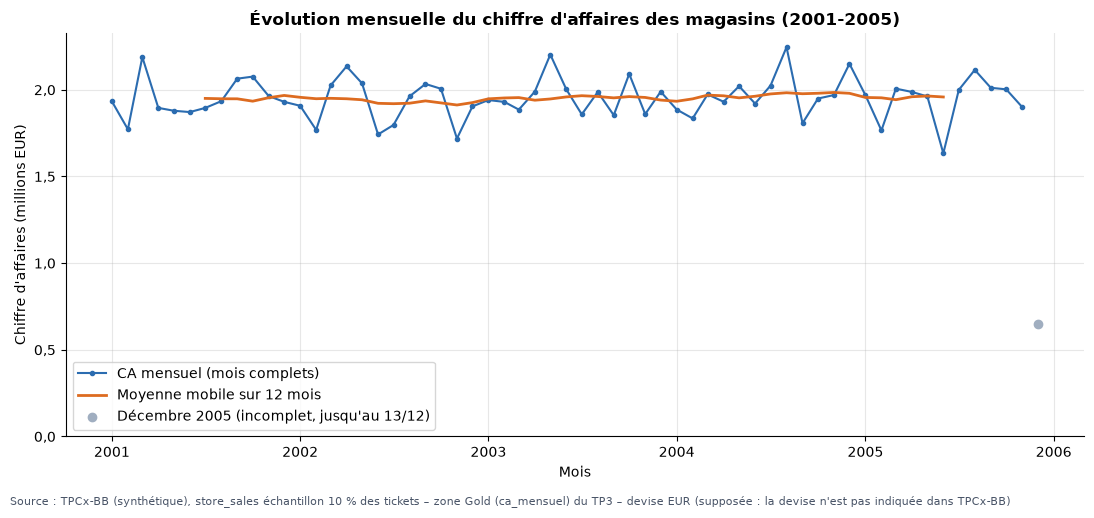

In [18]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(complets["periode"], complets["chiffre_affaires"], marker="o", markersize=3, color=COULEUR,
        label="CA mensuel (mois complets)")
moyenne_mobile = complets.set_index("periode")["chiffre_affaires"].rolling(12, center=True).mean()
ax.plot(moyenne_mobile.index, moyenne_mobile.values, color=COULEUR_2, linewidth=2, label="Moyenne mobile sur 12 mois")
incomplet = mensuel[mensuel["mois_incomplet"]]
ax.scatter(incomplet["periode"], incomplet["chiffre_affaires"], color=GRIS, zorder=3,
           label="Décembre 2005 (incomplet, jusqu'au 13/12)")
ax.yaxis.set_major_formatter(millions)
ax.set_ylim(bottom=0)
ax.set_title("Évolution mensuelle du chiffre d'affaires des magasins (2001-2005)", fontweight="bold")
ax.set_xlabel("Mois")
ax.set_ylabel("Chiffre d'affaires (millions EUR)")
ax.legend(loc="lower left")
source(fig, "Gold (ca_mensuel)")
fig.tight_layout()
enregistrer(fig, "evolution_ventes_mensuelles.png")
plt.show()

**Ce que montre le graphique** : le CA mensuel de janvier 2001 à novembre 2005, avec une moyenne mobile sur 12 mois. Décembre 2005 est en gris parce qu'il est incomplet.

**Résultat principal** : la moyenne mobile est presque plate, autour de 1,95 M EUR par mois. Les mois oscillent entre 1,6 et 2,25 M EUR sans tendance.

**Interprétation** : le CA est stable sur cinq ans. Le point bas de décembre 2005 (0,65 M EUR) ne traduit **pas** une chute des ventes : il manque simplement 18 jours.

**Limites** : l'axe vertical part de 0 pour ne pas exagérer les variations. Les données sont un échantillon de 10 %, et donc plus bruitées que le jeu complet.

### V2 – Chiffre d'affaires par catégorie (barres)

enregistre : analytics/visualizations/ca_par_categorie.png


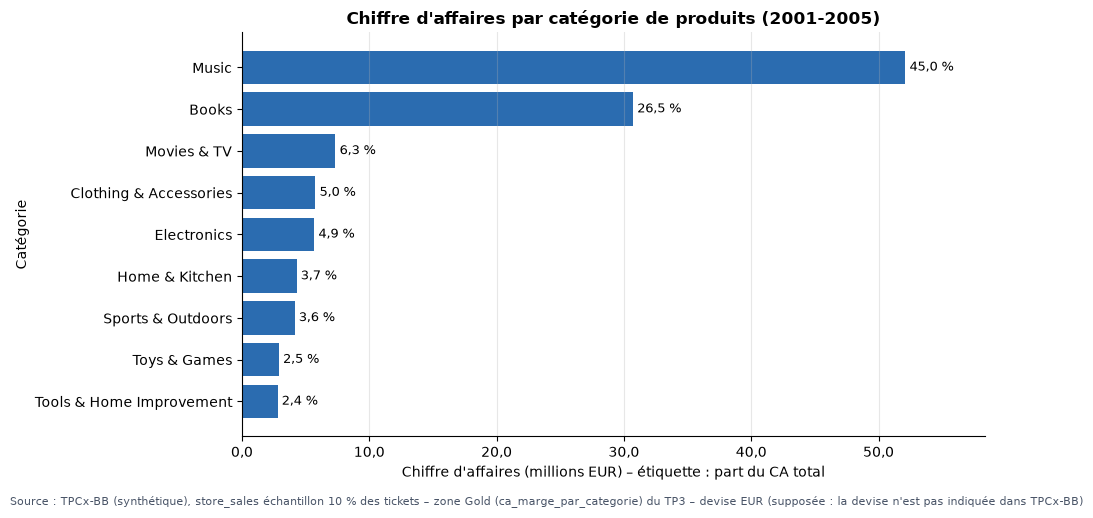

In [19]:
c = categories.sort_values("chiffre_affaires")
fig, ax = plt.subplots(figsize=(10, 5))
barres = ax.barh(c["categorie"], c["chiffre_affaires"], color=COULEUR)
ax.bar_label(barres, labels=[f"{p:.1f} %".replace(".", ",") for p in c["part_ca_pct"]], padding=3, fontsize=9)
ax.xaxis.set_major_formatter(millions)
ax.set_title("Chiffre d'affaires par catégorie de produits (2001-2005)", fontweight="bold")
ax.set_xlabel("Chiffre d'affaires (millions EUR) – étiquette : part du CA total")
ax.set_ylabel("Catégorie")
ax.grid(axis="y", visible=False)
ax.margins(x=0.12)
source(fig, "Gold (ca_marge_par_categorie)")
fig.tight_layout()
enregistrer(fig, "ca_par_categorie.png")
plt.show()

**Ce que montre le graphique** : le CA total 2001-2005 de chacune des 9 catégories, avec en étiquette la part du CA total.

**Résultat principal** : Music et Books dominent nettement (71,6 % du CA à elles deux).

**Interprétation** : l'activité dépend fortement de deux catégories. Une baisse sur l'une d'elles aurait un effet direct sur le CA total.

**Limites** : le graphique compare des montants, pas des marges. Il ne tient pas compte du nombre de produits proposés par catégorie (voir le CA par produit dans l'analyse A2).

### V3 – Chiffre d'affaires par magasin (barres)

enregistre : analytics/visualizations/ventes_par_magasin.png


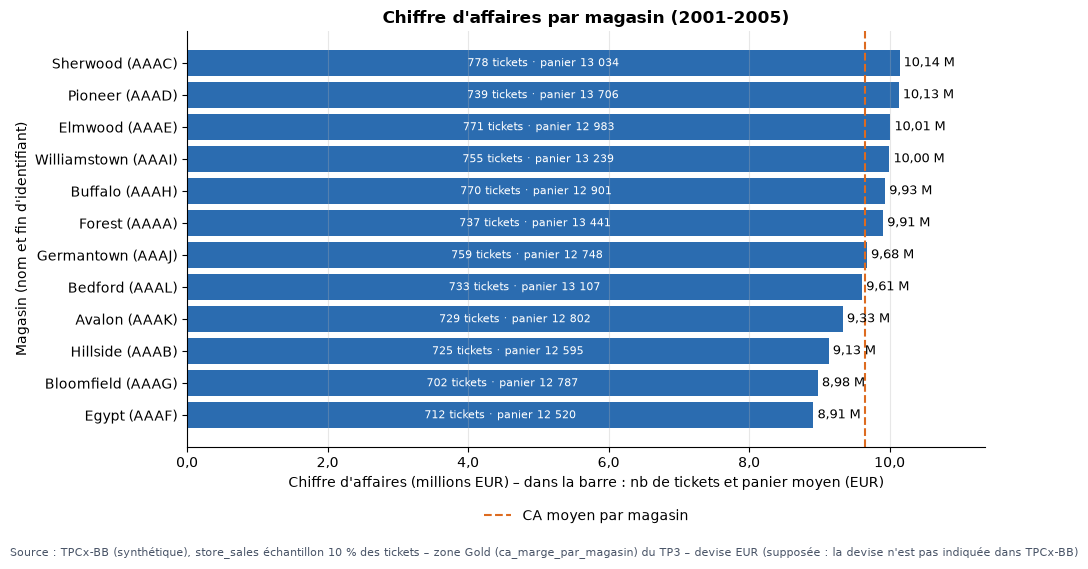

In [20]:
m = magasins.sort_values("chiffre_affaires")
fig, ax = plt.subplots(figsize=(10, 5.5))
barres = ax.barh(m["libelle"], m["chiffre_affaires"], color=COULEUR)
ax.bar_label(barres, labels=[f"{c / 1e6:.2f} M".replace(".", ",") for c in m["chiffre_affaires"]],
             padding=3, fontsize=9)
ax.bar_label(barres, labels=[f"{t} tickets · panier {p:,.0f}".replace(",", " ") for t, p in
                             zip(m["nb_transactions"], m["panier_moyen"])],
             label_type="center", color="white", fontsize=8)
ax.axvline(m["chiffre_affaires"].mean(), color=COULEUR_2, linestyle="--", linewidth=1.5, label="CA moyen par magasin")
ax.xaxis.set_major_formatter(millions)
ax.set_title("Chiffre d'affaires par magasin (2001-2005)", fontweight="bold")
ax.set_xlabel("Chiffre d'affaires (millions EUR) – dans la barre : nb de tickets et panier moyen (EUR)")
ax.set_ylabel("Magasin (nom et fin d'identifiant)")
ax.grid(axis="y", visible=False)
ax.margins(x=0.12)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
source(fig, "Gold (ca_marge_par_magasin)")
fig.tight_layout()
enregistrer(fig, "ventes_par_magasin.png")
plt.show()

**Ce que montre le graphique** : le CA 2001-2005 de chaque magasin, avec dans chaque barre le nombre de tickets et le panier moyen. La ligne pointillée indique le CA moyen par magasin (9,65 M EUR).

**Résultat principal** : les barres sont presque de même longueur. Le premier magasin ne dépasse le dernier que de 14 %.

**Interprétation** : le réseau est homogène. Le classement des magasins dépend surtout du nombre de tickets.

**Limites** : le graphique ne tient compte ni de la taille des magasins ni de leur effectif. Classer les magasins selon ce graphique serait abusif sans normalisation.

### V4 – Distribution du montant par ticket (histogramme)

Granularité : **un ticket** (8 910 valeurs). Le tableau des tickets est agrégé par Spark ; seule la colonne du montant passe dans Pandas.

enregistre : analytics/visualizations/distribution_montant_tickets.png


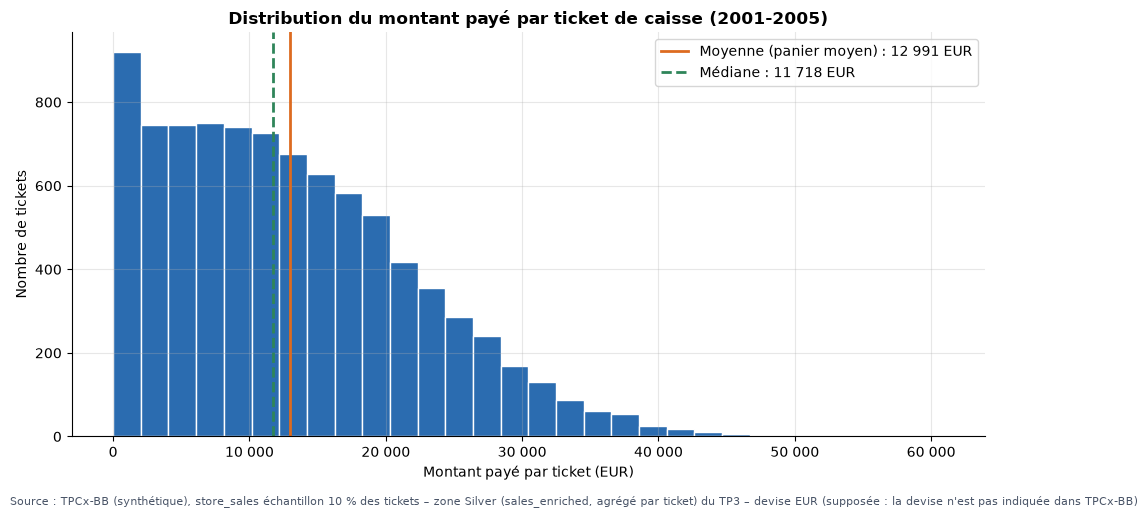

Tickets sous 1 000 EUR : 6.0 % | au-dessus de 10 000 EUR : 56.7 %


In [21]:
pdf_tickets = tickets.select("montant_ticket").toPandas()["montant_ticket"].astype(float)
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(pdf_tickets, bins=A["classes_histogramme"], color=COULEUR, edgecolor="white")
ax.axvline(pdf_tickets.mean(), color=COULEUR_2, linewidth=2, label=f"Moyenne (panier moyen) : {pdf_tickets.mean():,.0f} EUR".replace(",", " "))
ax.axvline(pdf_tickets.median(), color="#2f855a", linewidth=2, linestyle="--",
           label=f"Médiane : {pdf_tickets.median():,.0f} EUR".replace(",", " "))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
ax.set_title("Distribution du montant payé par ticket de caisse (2001-2005)", fontweight="bold")
ax.set_xlabel("Montant payé par ticket (EUR)")
ax.set_ylabel("Nombre de tickets")
ax.legend()
source(fig, "Silver (sales_enriched, agrégé par ticket)")
fig.tight_layout()
enregistrer(fig, "distribution_montant_tickets.png")
plt.show()
print("Tickets sous 1 000 EUR :", round((pdf_tickets < 1000).mean() * 100, 1), "%",
      "| au-dessus de 10 000 EUR :", round((pdf_tickets > 10000).mean() * 100, 1), "%")

**Ce que montre le graphique** : la distribution du montant payé par ticket (8 910 tickets), avec la moyenne (panier moyen, KPI-03) et la médiane.

**Résultat principal** : la distribution est **asymétrique à droite**. La moyenne (12 991 EUR) est supérieure à la médiane (11 718 EUR), et quelques tickets dépassent 40 000 EUR. 56,7 % des tickets dépassent 10 000 EUR et 6,0 % sont sous 1 000 EUR.

**Interprétation** : le panier moyen est tiré vers le haut par les gros tickets. La médiane décrit mieux un ticket « typique ».

**Limites** : ces montants (380 articles par ticket en moyenne) ne sont pas réalistes pour un magasin : ils viennent du générateur TPCx-BB. La forme de la distribution reste utile pour la démarche, pas pour décrire des clients réels.

## 6. Étape 6 – Constats, limites et recommandations

Rappel : TPCx-BB est un jeu **synthétique**. Ces constats illustrent une démarche d'analyse et ne décrivent pas une entreprise réelle. Une corrélation ne démontre pas une causalité.

### Constat 1 – Le chiffre d'affaires des magasins est stable, sans croissance

| | |
|---|---|
| **Résultat observé** | CA annuel entre 23,0 et 23,7 M EUR (2001-2004). Évolution annuelle sur période égale de −1,7 % à +2,8 %, et −2,5 % en 2005 (−7,2 % en brut). Variations mensuelles de ±15 % sans tendance. Les écarts entre mois s'expliquent par leur nombre de jours. |
| **Interprétation possible** | Activité plate. Le −7,2 % de 2005 vient surtout du mois de décembre incomplet, pas d'un décrochage. |
| **Limite** | Échantillon de 10 % des tickets, retours non déduits, canal web absent, données synthétiques. |
| **Recommandation** | Toujours présenter l'évolution N/N-1 **sur période égale** et le **CA par jour de vente** plutôt que le CA mensuel brut. Confirmer la légère baisse de 2005 (−2,5 %) sur le fichier complet avant d'en tirer une conclusion. |

### Constat 2 – Deux catégories font 72 % du CA, grâce à leur assortiment

| | |
|---|---|
| **Résultat observé** | Music 45,0 % et Books 26,5 % du CA. Ce sont aussi les catégories avec le plus de produits (7 164 et 4 688 sur 15 636). Leur CA par produit est inférieur à celui de Clothing, Sports ou Home & Kitchen. Le taux de remise est identique partout (≈ 50 %). |
| **Interprétation possible** | Forte dépendance à deux catégories, qui pèsent par leur largeur de gamme plutôt que par la performance de chaque produit. |
| **Limite** | Marge inutilisable (coûts générés) : on ne sait pas si ces catégories sont rentables. Le lien assortiment → CA est une observation, pas une cause démontrée. |
| **Recommandation** | Suivre ces deux catégories en priorité (alerte en cas de baisse). Étudier, avec des coûts fiables, si élargir l'offre des catégories à fort CA par produit (Clothing, Sports, Home & Kitchen) serait intéressant. |

### Constat 3 – Les magasins sont homogènes, leurs écarts viennent de la fréquentation

| | |
|---|---|
| **Résultat observé** | 12 magasins entre 8,91 et 10,14 M EUR (max / min = 1,14 ; coefficient de variation 4,7 %), tous actifs sur toute la période. Le CA est plus lié au nombre de tickets (r = 0,84) qu'au panier moyen (r = 0,74). |
| **Interprétation possible** | Aucun magasin ne décroche. Le meilleur magasin attire un peu plus de tickets. |
| **Limite** | 12 points seulement, une corrélation qui n'est pas une causalité, et un CA non rapporté à la surface ni à l'effectif. |
| **Recommandation** | Avant tout classement ou toute décision par magasin, calculer le **CA par m²** (`s_floor_space`) et le **CA par employé** (`s_number_employees`), disponibles dans le Silver `stores`. |

### Limites générales

* **Canal web absent** : `web_sales` n'a pas été transformé au TP3, donc la question P1 « part magasin / web » reste sans réponse.
* **Échantillon** de 10 % des tickets (`ss_ticket_number` multiple de 10). Les totaux correspondent à environ un dixième du réseau.
* **Marge** non retenue (74 % de lignes à marge négative), **devise** supposée en euros, **retours** non déduits.
* **Paniers irréalistes** (380 articles par ticket) dus au générateur : utiliser la médiane en plus de la moyenne.

## 7. Tests de validation UC-08 (§ 12.1 du TP)

In [22]:
fichiers_attendus = ["inventaire_jeux.csv", "kpi_dictionnaire.csv", "kpi.csv", "statistiques.csv",
                     "analyse_ca_mensuel.csv", "analyse_categories.csv", "ventes_par_magasin.csv"]
graphes = ["evolution_ventes_mensuelles.png", "ca_par_categorie.png", "ventes_par_magasin.png",
           "distribution_montant_tickets.png"]
tests = [
    ("Les jeux de donnees utilises sont identifies", len(pdf_inventaire) >= 2, "analytics/outputs/inventaire_jeux.csv"),
    ("Les schemas et granularites ont ete verifies", bool(pdf_inventaire["cle_unique"].all()), "etape 1 : cle unique par jeu"),
    ("Les KPI disposent d'une definition explicite", (pdf_kpi_dico["statut"] == "calcule").sum() >= 3, "analytics/outputs/kpi_dictionnaire.csv"),
    ("Les calculs sont reproductibles", bool(pdf_ctrl_kpi["silver = gold"].all()), "KPI Silver = Gold ca_annuel"),
    ("Les statistiques sont coherentes avec les donnees",
     int(pdf_stats.loc[pdf_stats.variable == "lignes_par_ticket", "somme"].isna().all()) == 1
     and int(pdf_stats.loc[pdf_stats.variable == "quantite", "nb_valeurs"].iloc[0]) == pdf_inventaire.loc[0, "lignes"]
     and round(pdf_stats.loc[pdf_stats.variable == "montant_ticket", "somme"].iloc[0], 2) == round(float(total["chiffre_affaires"][0]), 2),
     "somme des tickets = CA ; nb valeurs = nb lignes"),
    ("Les visualisations sont lisibles et legendees", all((VISU / g).exists() for g in graphes), "analytics/visualizations/*.png"),
    ("Les exports sont presents", all((OUTPUTS / f).exists() for f in fichiers_attendus), "analytics/outputs/*.csv"),
]
pdf_tests = pd.DataFrame(tests, columns=["controle", "ok", "preuve"])
pdf_tests.to_csv(OUTPUTS / "tests_uc08.csv", index=False)
assert pdf_tests["ok"].all(), pdf_tests
pdf_tests

,controle,ok,preuve
0,Les jeux de donnees utilises sont identifies,True,analytics/outputs/inventaire_jeux.csv
1,Les schemas et granularites ont ete verifies,True,etape 1 : cle unique par jeu
2,Les KPI disposent d'une definition explicite,True,analytics/outputs/kpi_dictionnaire.csv
3,Les calculs sont reproductibles,True,KPI Silver = Gold ca_annuel
4,Les statistiques sont coherentes avec les donnees,True,somme des tickets = CA ; nb valeurs = nb lignes
5,Les visualisations sont lisibles et legendees,True,analytics/visualizations/*.png
6,Les exports sont presents,True,analytics/outputs/*.csv


Les deux derniers critères du § 12.1 (*interprétations justifiées*, *limites mentionnées*) sont vérifiés par la lecture : chaque analyse et chaque graphique sont suivis d'une interprétation et de leurs limites, reprises dans `docs/analytics/interpretation.md`.

In [23]:
spark.stop()